# 02 · Exploratory analysis (200k student sample)
**Question:** when, where and with whom is a business trip most likely to be disrupted?

Every table reports the number of flights, the disruption rate with a 95% Wilson confidence
interval, and hides groups with fewer than 100 flights. *Disrupted* = arrived 15+ min late,
cancelled or diverted. *Severe* = 60+ min late, cancelled or diverted.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import prep, style
from style import INK, GREY, ACCENT, GOOD, BLUE, AMBER, PCT
style.use()
pd.set_option("display.width", 200, "display.max_columns", 60, "display.float_format", "{:.3f}".format)

df = pd.read_parquet(prep.PROCESSED / "flights_sample.parquet")
BASE = df.disrupted.mean()
print(f"{len(df):,} flights | disrupted {BASE:.1%} | severe {df.severe.mean():.1%} | cancelled {df.CANCELLED.mean():.2%}")

def show(by, min_n=100, save=None, sort=None):
    t = prep.rate_table(df, by, min_n)
    if sort: t = t.sort_values(sort)
    if save: t.to_csv(prep.TABLES / f"{save}.csv")
    return t

200,000 flights | disrupted 23.5% | severe 9.7% | cancelled 1.45%


## 1. What does a "typical" delay look like?

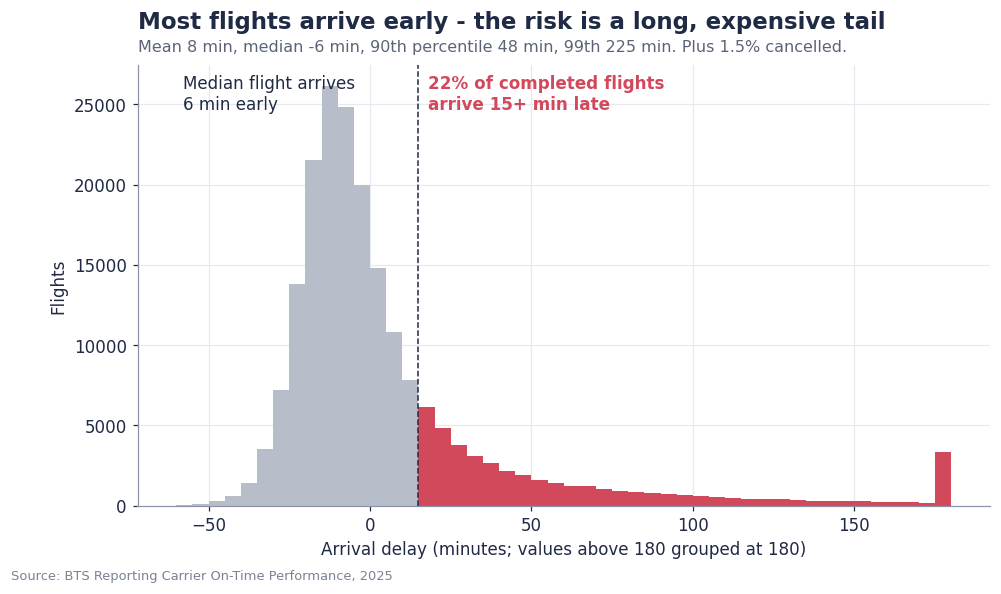

In [2]:
c = df[df.completed == 1].ARR_DELAY
fig, ax = plt.subplots()
ax.hist(c.clip(-60, 180), bins=np.arange(-60, 185, 5), color=GREY)
ax.hist(c[c >= 15].clip(upper=180), bins=np.arange(15, 185, 5), color=ACCENT)
ax.axvline(15, color=INK, lw=1, ls="--")
ax.text(18, ax.get_ylim()[1] * .9, f"{(c >= 15).mean():.0%} of completed flights\narrive 15+ min late", color=ACCENT, fontweight="bold")
ax.text(-58, ax.get_ylim()[1] * .9, f"Median flight arrives\n{abs(c.median()):.0f} min early", color=INK)
ax.set_xlabel("Arrival delay (minutes; values above 180 grouped at 180)"); ax.set_ylabel("Flights")
style.titled(ax, "Most flights arrive early - the risk is a long, expensive tail",
             f"Mean {c.mean():.0f} min, median {c.median():.0f} min, 90th percentile {c.quantile(.9):.0f} min, 99th {c.quantile(.99):.0f} min. Plus {df.CANCELLED.mean():.1%} cancelled.")
style.save(fig, "01_delay_distribution");

## 2. Time of day - the biggest lever

In [3]:
hr = show("dep_hour", save="by_dep_hour")
hr

,n,disrupted,severe,cancelled,mean_arr_delay,p90_arr_delay,disrupted_lo,disrupted_hi,severe_lo,severe_hi
dep_hour,,,,,,,,,,
0,270,0.126,0.052,0.015,-7.701,15.000,0.092,0.171,0.031,0.085
5,5695,0.102,0.049,0.017,-2.930,12.000,0.095,0.111,0.043,0.055
6,13654,0.110,0.047,0.013,-2.528,14.000,0.105,0.116,0.043,0.050
7,14760,0.138,0.052,0.011,-0.996,21.000,0.132,0.144,0.048,0.056
8,13855,0.151,0.055,0.010,0.546,24.000,0.145,0.157,0.052,0.059
9,11185,0.173,0.062,0.011,1.835,28.000,0.166,0.180,0.058,0.067
10,12412,0.187,0.071,0.011,3.220,34.000,0.180,0.194,0.067,0.076
11,12399,0.202,0.076,0.009,4.935,38.000,0.195,0.210,0.071,0.081
12,11791,0.212,0.083,0.011,6.196,41.700,0.205,0.219,0.078,0.088


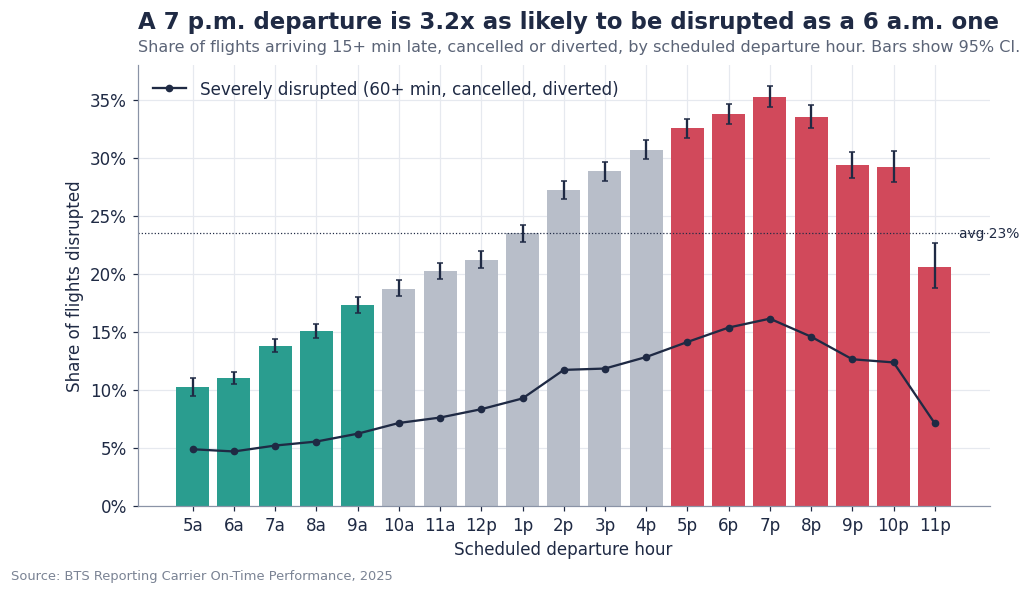

In [4]:
h = hr.loc[5:23]
fig, ax = plt.subplots()
cols = [GOOD if x <= 9 else (ACCENT if x >= 17 else GREY) for x in h.index]
ax.bar(h.index, h.disrupted, color=cols, yerr=[h.disrupted - h.disrupted_lo, h.disrupted_hi - h.disrupted], ecolor=INK, capsize=2)
ax.plot(h.index, h.severe, color=INK, marker="o", ms=4, lw=1.5, label="Severely disrupted (60+ min, cancelled, diverted)")
ax.axhline(BASE, color=INK, lw=.8, ls=":"); ax.text(23.6, BASE, f"avg {BASE:.0%}", va="center", fontsize=9)
ax.set_xticks(range(5, 24)); ax.set_xticklabels([f"{x % 12 or 12}{'a' if x < 12 else 'p'}" for x in range(5, 24)])
ax.yaxis.set_major_formatter(PCT); ax.set_xlabel("Scheduled departure hour"); ax.set_ylabel("Share of flights disrupted"); ax.legend(loc="upper left")
style.titled(ax, f"A 7 p.m. departure is {h.disrupted[19] / h.disrupted[6]:.1f}x as likely to be disrupted as a 6 a.m. one",
             "Share of flights arriving 15+ min late, cancelled or diverted, by scheduled departure hour. Bars show 95% CI.")
style.save(fig, "02_disruption_by_hour");

time_band,Early (5-6:59a),Morning (7-9:59a),Midday (10a-1:59p),Afternoon (2-5:59p),Evening (6-9:59p),Late night (10p-4:59a)
dow_name,,,,,,
Mon,0.119,0.166,0.231,0.319,0.335,0.269
Tue,0.104,0.136,0.178,0.248,0.271,0.218
Wed,0.093,0.132,0.183,0.264,0.282,0.193
Thu,0.095,0.140,0.202,0.323,0.379,0.278
Fri,0.103,0.151,0.219,0.319,0.352,0.254
Sat,0.128,0.169,0.206,0.267,0.293,0.224
Sun,0.115,0.172,0.241,0.348,0.402,0.348


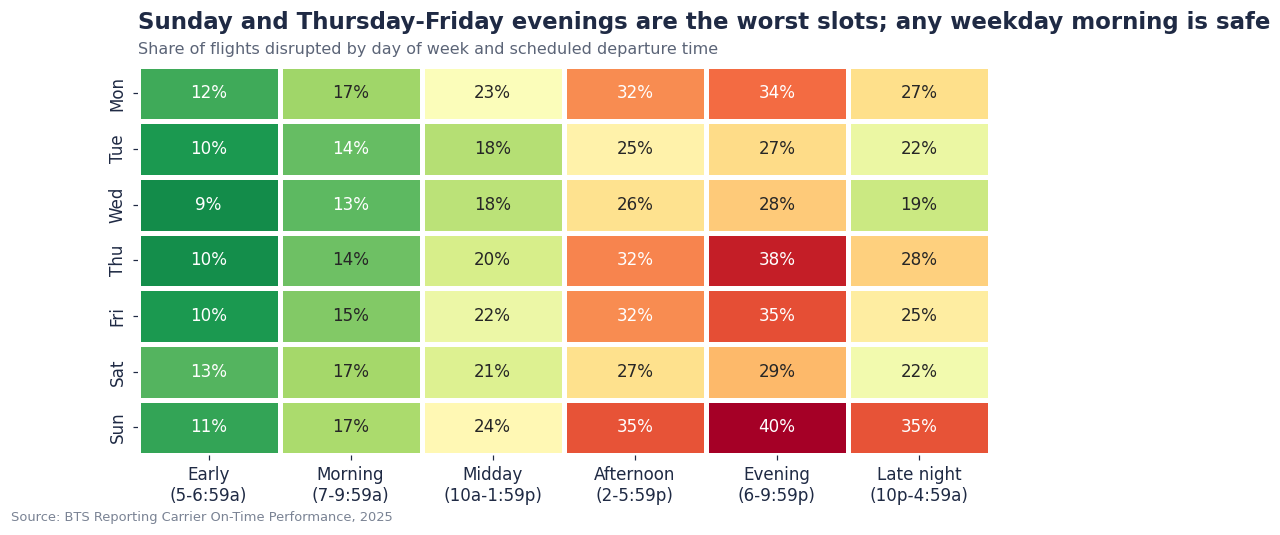

In [5]:
pv = df.pivot_table(index="dow_name", columns="time_band", values="disrupted", aggfunc="mean", observed=True)
fig, ax = plt.subplots(figsize=(10, 4.6))
sns.heatmap(pv, annot=True, fmt=".0%", cmap="RdYlGn_r", center=BASE, cbar=False, linewidths=2, linecolor="white", ax=ax, annot_kws={"fontsize": 11})
ax.set_xlabel(""); ax.set_ylabel(""); ax.grid(False)
ax.set_xticklabels([t.get_text().replace(" (", "\n(") for t in ax.get_xticklabels()], rotation=0)
style.titled(ax, "Sunday and Thursday-Friday evenings are the worst slots; any weekday morning is safe",
             "Share of flights disrupted by day of week and scheduled departure time")
style.save(fig, "03_heatmap_day_by_time");
pv.round(3)

## 3. Season and cancellation causes

,n,disrupted,severe,cancelled,mean_arr_delay,p90_arr_delay,disrupted_lo,disrupted_hi,severe_lo,severe_hi
MONTH,,,,,,,,,,
1,15349,0.216,0.097,0.032,4.022,37.000,0.209,0.222,0.093,0.102
2,14402,0.222,0.087,0.013,5.712,44.000,0.216,0.229,0.083,0.092
3,17059,0.208,0.081,0.009,5.414,41.000,0.202,0.215,0.077,0.086
4,16656,0.204,0.079,0.008,5.718,39.000,0.198,0.211,0.075,0.083
5,17235,0.242,0.095,0.011,9.918,49.000,0.236,0.249,0.091,0.100
6,17360,0.296,0.134,0.017,15.579,67.000,0.289,0.302,0.129,0.139
7,17819,0.312,0.150,0.026,17.353,72.000,0.305,0.318,0.145,0.156
8,17168,0.236,0.095,0.012,8.912,47.300,0.230,0.242,0.091,0.100
9,16071,0.171,0.060,0.005,1.840,30.000,0.165,0.177,0.057,0.064


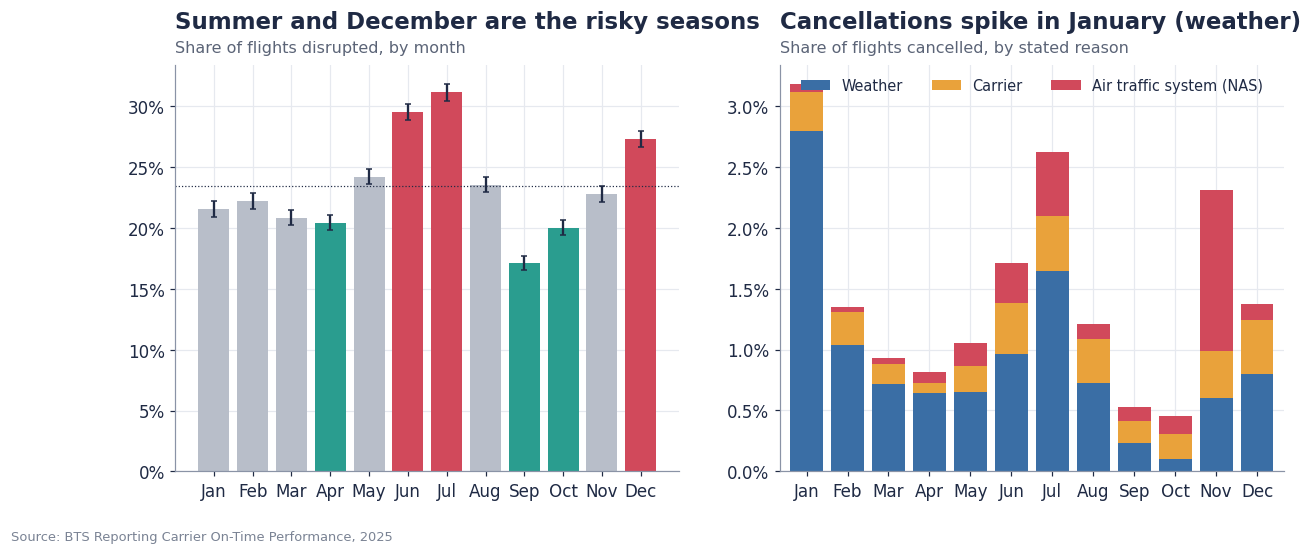

In [6]:
mo = show("MONTH", save="by_month")
cc = pd.crosstab(df.MONTH, df.CANCELLATION_CODE.map({"A": "Carrier", "B": "Weather", "C": "Air traffic system (NAS)", "D": "Security"}))
cc = cc.div(df.groupby("MONTH").size(), axis=0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
mn = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
a1.bar(mn, mo.disrupted, color=[ACCENT if v > BASE + .03 else (GOOD if v < BASE - .03 else GREY) for v in mo.disrupted],
       yerr=[mo.disrupted - mo.disrupted_lo, mo.disrupted_hi - mo.disrupted], ecolor=INK, capsize=2)
a1.axhline(BASE, color=INK, lw=.8, ls=":"); a1.yaxis.set_major_formatter(PCT)
style.titled(a1, "Summer and December are the risky seasons", "Share of flights disrupted, by month")
cc[["Weather", "Carrier", "Air traffic system (NAS)"]].set_axis(mn).plot.bar(stacked=True, ax=a2, color=[BLUE, AMBER, ACCENT], width=.8, rot=0)
a2.yaxis.set_major_formatter(style.PercentFormatter(1.0, decimals=1)); a2.set_xlabel(""); a2.legend(title=None, loc="upper center", ncol=3, fontsize=9.5, bbox_to_anchor=(.5, 1.0))
style.titled(a2, "Cancellations spike in January (weather)", "Share of flights cancelled, by stated reason")
style.save(fig, "04_month_and_cancellations");
mo

## 4. Carrier

,CARRIER,carrier_name,regional,n,disrupted,severe,cancelled,mean_arr_delay,p90_arr_delay,disrupted_lo,disrupted_hi,severe_lo,severe_hi
0,DL,Delta,0,32059,0.205,0.085,0.010,5.880,41.000,0.201,0.210,0.082,0.089
1,OO,SkyWest,1,26102,0.219,0.101,0.013,9.140,49.000,0.214,0.224,0.098,0.105
2,UA,United,0,24950,0.224,0.089,0.008,6.755,45.000,0.219,0.229,0.086,0.093
3,WN,Southwest,0,43668,0.224,0.075,0.008,6.142,41.000,0.220,0.228,0.072,0.077
4,MQ,Envoy,1,9384,0.235,0.094,0.024,6.221,42.000,0.226,0.243,0.088,0.100
5,AS,Alaska,0,7717,0.238,0.068,0.013,4.637,37.000,0.229,0.248,0.063,0.074
6,YX,Republic,1,10626,0.241,0.123,0.033,6.481,53.000,0.233,0.249,0.117,0.130
7,AA,American,0,30271,0.271,0.118,0.018,13.689,59.000,0.266,0.276,0.115,0.122
8,B6,JetBlue,0,7333,0.282,0.139,0.017,12.139,70.000,0.272,0.292,0.131,0.147
9,OH,PSA,1,7890,0.312,0.165,0.042,18.530,78.000,0.302,0.322,0.157,0.173


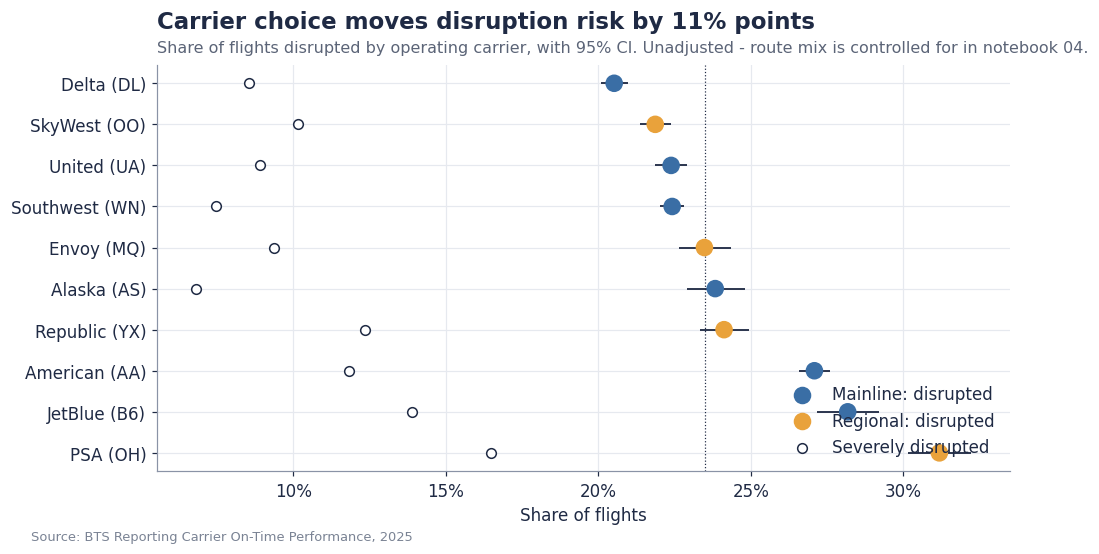

In [7]:
ca = show(["CARRIER", "carrier_name", "regional"], save="by_carrier", sort="disrupted").reset_index()
fig, ax = plt.subplots(figsize=(10, 4.8))
y = np.arange(len(ca))
ax.hlines(y, ca.disrupted_lo, ca.disrupted_hi, color=INK, lw=1.2)
ax.scatter(ca.disrupted, y, s=110, color=[AMBER if r else BLUE for r in ca.regional], zorder=3)
ax.scatter(ca.severe, y, s=40, color="white", edgecolor=INK, zorder=3)
ax.set_yticks(y); ax.set_yticklabels([f"{n} ({c})" for n, c in zip(ca.carrier_name, ca.CARRIER)]); ax.invert_yaxis()
ax.axvline(BASE, color=INK, lw=.8, ls=":"); ax.xaxis.set_major_formatter(PCT); ax.set_xlabel("Share of flights")
ax.scatter([], [], s=110, color=BLUE, label="Mainline: disrupted"); ax.scatter([], [], s=110, color=AMBER, label="Regional: disrupted")
ax.scatter([], [], s=40, color="white", edgecolor=INK, label="Severely disrupted"); ax.legend(loc="lower right")
style.titled(ax, f"Carrier choice moves disruption risk by {ca.disrupted.max() - ca.disrupted.min():.0%} points",
             "Share of flights disrupted by operating carrier, with 95% CI. Unadjusted - route mix is controlled for in notebook 04.")
style.save(fig, "05_carrier");
ca

## 5. Airports

,n,disrupted,severe,cancelled,mean_arr_delay,p90_arr_delay,disrupted_lo,disrupted_hi,severe_lo,severe_hi
ORIGIN,,,,,,,,,,
DFW,9396,0.314,0.140,0.028,15.186,66.900,0.305,0.324,0.133,0.147
DCA,4331,0.302,0.156,0.035,15.204,74.600,0.289,0.316,0.146,0.167
LGA,3915,0.285,0.137,0.029,12.098,66.000,0.271,0.299,0.127,0.148
ORD,9819,0.284,0.131,0.018,13.435,65.000,0.275,0.293,0.124,0.137
MIA,3297,0.277,0.109,0.013,11.248,57.000,0.262,0.292,0.099,0.120
EWR,3498,0.271,0.133,0.025,10.470,66.000,0.257,0.286,0.122,0.144
JFK,3148,0.269,0.120,0.022,8.096,57.000,0.254,0.285,0.109,0.132
PHL,2604,0.268,0.123,0.018,11.162,61.000,0.252,0.286,0.110,0.136
DEN,9329,0.263,0.097,0.006,10.884,53.000,0.254,0.272,0.091,0.103


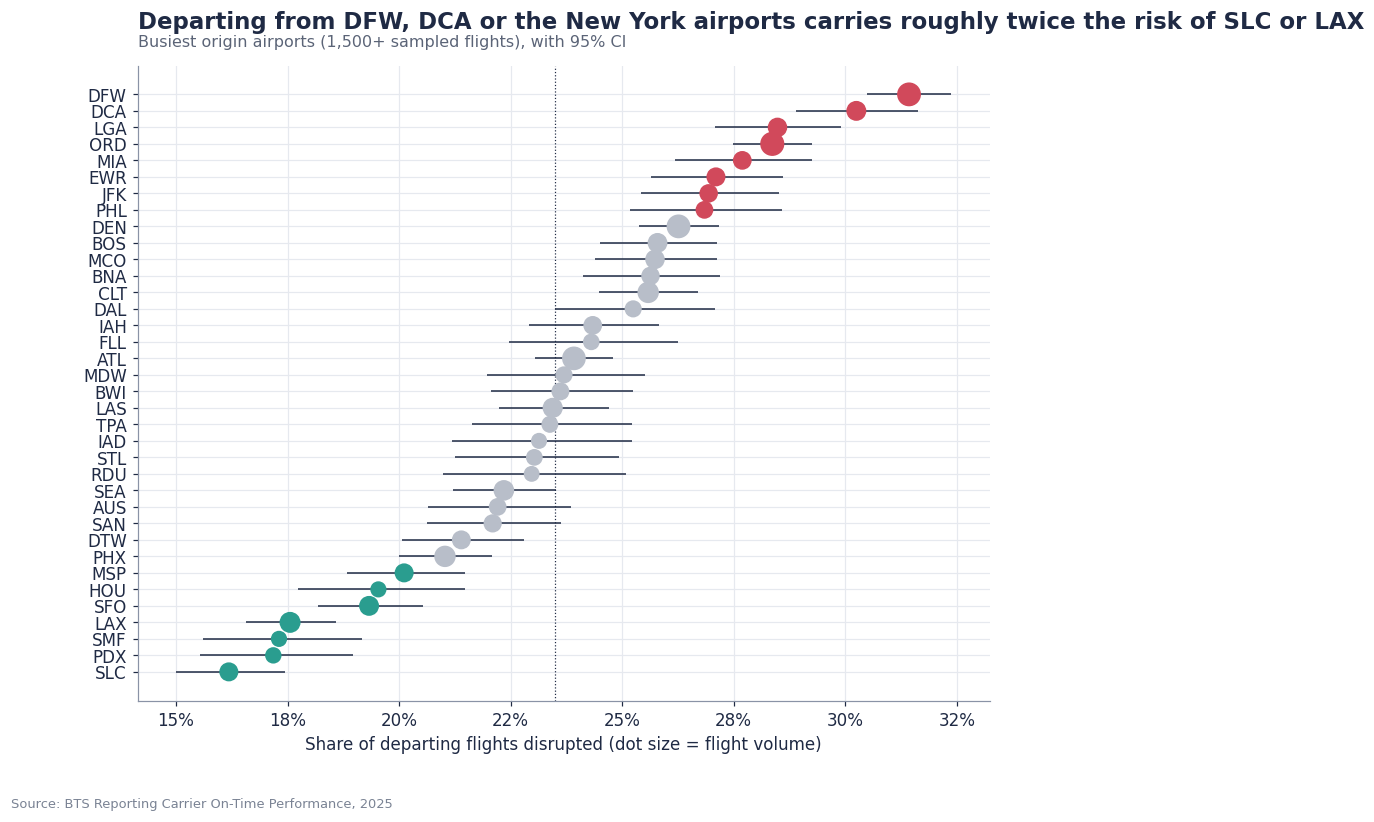

In [8]:
ap = show("ORIGIN", min_n=1500, save="by_origin_top", sort="disrupted")
fig, ax = plt.subplots(figsize=(10, 7.5))
y = np.arange(len(ap))
ax.hlines(y, ap.disrupted_lo, ap.disrupted_hi, color=INK, lw=1)
ax.scatter(ap.disrupted, y, s=np.sqrt(ap.n) * 2.2, color=[ACCENT if v > BASE + .03 else (GOOD if v < BASE - .03 else GREY) for v in ap.disrupted], zorder=3)
ax.set_yticks(y); ax.set_yticklabels(ap.index); ax.axvline(BASE, color=INK, lw=.8, ls=":"); ax.xaxis.set_major_formatter(PCT)
ax.set_xlabel("Share of departing flights disrupted (dot size = flight volume)")
style.titled(ax, "Departing from DFW, DCA or the New York airports carries roughly twice the risk of SLC or LAX",
             "Busiest origin airports (1,500+ sampled flights), with 95% CI")
style.save(fig, "06_airports");
ap.sort_values("disrupted", ascending=False).head(10)

## 6. Things that matter less than people think

n  disrupted  disrupted_lo  disrupted_hi  severe  cancelled
distance         <250        22577      0.232         0.226         0.237   0.105      0.021
                 250-500     47957      0.226         0.223         0.230   0.096      0.016
                 500-1k      70897      0.240         0.237         0.243   0.101      0.015
                 1k-1.5k     31586      0.248         0.244         0.253   0.100      0.012
                 1.5k-2.5k   22872      0.226         0.221         0.232   0.083      0.008
                 2.5k+        4111      0.213         0.201         0.226   0.072      0.007
regional carrier 0          145998      0.233         0.231         0.235   0.091      0.011
                 1           54002      0.239         0.236         0.243   0.114      0.023
holiday window   0          174392      0.232         0.230         0.234   0.096      0.014
                 1           25608      0.255         0.249         0.260   0.106      0.015
day of week      Mon         29656      0.250         0.245         0.255   0.102      0.014
                 Tue         27825      0.197         0.193         0.202   0.079      0.012
                 Wed         28224      0.203         0.198         0.208   0.084      0.012
                 Thu         29262      0.246         0.241         0.251   0.100      0.016
                 Fri         29554      0.244         0.240         0.249   0.102      0.015
                 Sat         26100      0.221         0.216         0.226   0.090      0.015
                 Sun         29379      0.279         0.274         0.284   0.124      0.017

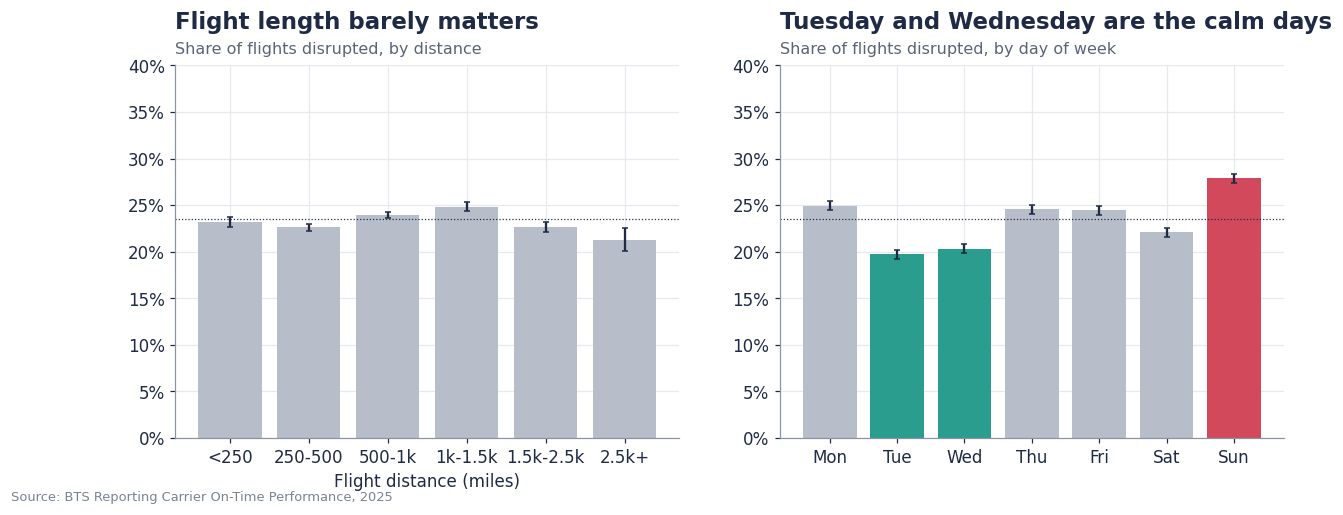

In [9]:
di = show("dist_band", save="by_distance")
rg = show("regional"); hw = show("holiday_window"); wk = show("dow_name", save="by_dow")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.4))
a1.bar(di.index.astype(str), di.disrupted, color=GREY, yerr=[di.disrupted - di.disrupted_lo, di.disrupted_hi - di.disrupted], ecolor=INK, capsize=2)
a1.axhline(BASE, color=INK, lw=.8, ls=":"); a1.yaxis.set_major_formatter(PCT); a1.set_ylim(0, .4); a1.set_xlabel("Flight distance (miles)")
style.titled(a1, "Flight length barely matters", "Share of flights disrupted, by distance")
a2.bar(wk.index.astype(str), wk.disrupted, color=[ACCENT if v > BASE + .02 else (GOOD if v < BASE - .02 else GREY) for v in wk.disrupted],
       yerr=[wk.disrupted - wk.disrupted_lo, wk.disrupted_hi - wk.disrupted], ecolor=INK, capsize=2)
a2.axhline(BASE, color=INK, lw=.8, ls=":"); a2.yaxis.set_major_formatter(PCT); a2.set_ylim(0, .4)
style.titled(a2, "Tuesday and Wednesday are the calm days", "Share of flights disrupted, by day of week")
style.save(fig, "07_distance_and_weekday");
pd.concat({"distance": di, "regional carrier": rg, "holiday window": hw, "day of week": wk})[["n", "disrupted", "disrupted_lo", "disrupted_hi", "severe", "cancelled"]]

## 7. Why do delays build through the day?
Average delay minutes per flight, split by the cause the airline reported.

Late inbound aircraft         0.390
Airline (crew, maintenance)   0.328
Air traffic system            0.216
Extreme weather               0.065
Security                      0.001
dtype: float64

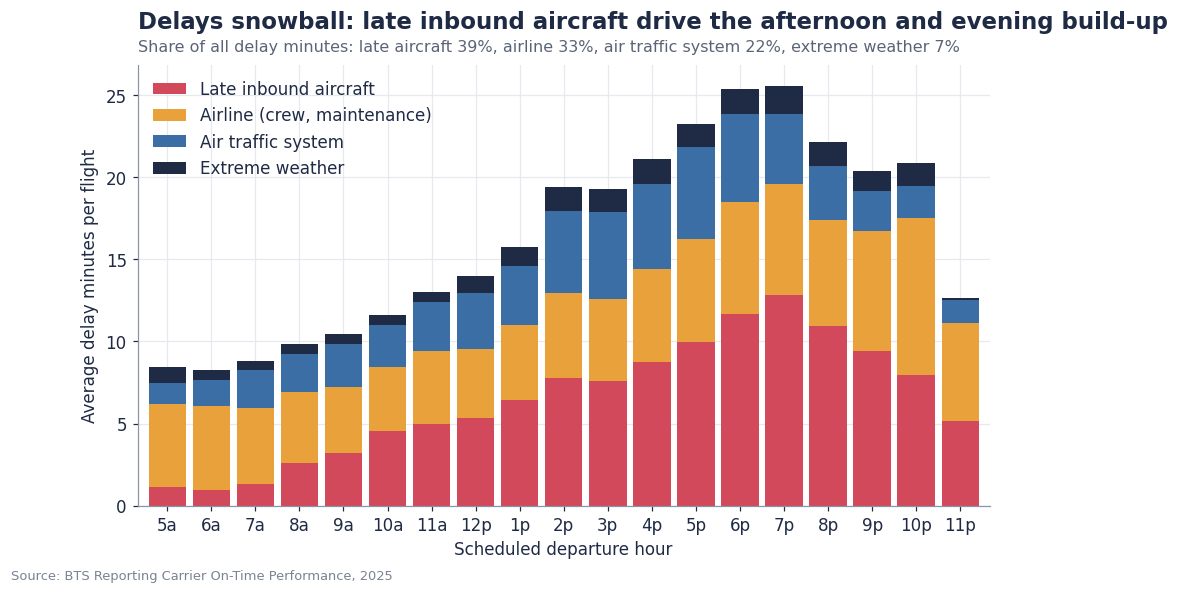

In [10]:
causes = {"LATE_AIRCRAFT_DELAY": "Late inbound aircraft", "CARRIER_DELAY": "Airline (crew, maintenance)", "NAS_DELAY": "Air traffic system", "WEATHER_DELAY": "Extreme weather", "SECURITY_DELAY": "Security"}
cm = df[df.completed == 1].assign(**{c: lambda d, c=c: d[c].fillna(0) for c in causes}).groupby("dep_hour")[list(causes)].mean().loc[5:23].rename(columns=causes)
share = df[list(causes)].sum() / df[list(causes)].sum().sum()
fig, ax = plt.subplots()
cm.iloc[:, :4].plot.bar(stacked=True, ax=ax, color=[ACCENT, AMBER, BLUE, INK], width=.85, rot=0)
ax.set_xticklabels([f"{x % 12 or 12}{'a' if x < 12 else 'p'}" for x in cm.index]); ax.set_xlabel("Scheduled departure hour"); ax.set_ylabel("Average delay minutes per flight")
style.titled(ax, "Delays snowball: late inbound aircraft drive the afternoon and evening build-up",
             f"Share of all delay minutes: late aircraft {share.iloc[0]:.0%}, airline {share.iloc[1]:.0%}, air traffic system {share.iloc[2]:.0%}, extreme weather {share.iloc[3]:.0%}")
style.save(fig, "08_delay_causes_by_hour");
share.rename(index=causes).round(3)

## 8. Are the patterns driven by a few bad days?

In [11]:
day = df.groupby("FL_DATE").agg(n=("disrupted", "size"), disrupted=("disrupted", "mean"), cancelled=("CANCELLED", "mean"))
worst = day.sort_values("cancelled", ascending=False).head(15)
calm = df[~df.FL_DATE.isin(worst.index)]
rob = pd.DataFrame({
    "all days": [df.disrupted.mean(), df[df.dep_hour.between(5, 9)].disrupted.mean(), df[df.dep_hour.between(17, 21)].disrupted.mean(), df.CANCELLED.mean()],
    "excluding 15 worst days": [calm.disrupted.mean(), calm[calm.dep_hour.between(5, 9)].disrupted.mean(), calm[calm.dep_hour.between(17, 21)].disrupted.mean(), calm.CANCELLED.mean()],
}, index=["disrupted - all flights", "disrupted - 5-9:59 a.m.", "disrupted - 5-9:59 p.m.", "cancelled"])
rob.to_csv(prep.TABLES / "robustness_event_days.csv")
print(worst.round(3)); rob.round(4)

              n  disrupted  cancelled
FL_DATE                              
2025-01-10  538      0.414      0.169
2025-11-09  579      0.522      0.116
2025-01-21  441      0.320      0.113
2025-01-09  513      0.310      0.109
2025-01-06  544      0.480      0.094
2025-07-14  591      0.431      0.085
2025-11-10  535      0.449      0.084
2025-01-22  503      0.243      0.080
2025-01-05  541      0.357      0.079
2025-07-31  555      0.445      0.079
2025-06-28  521      0.361      0.073
2025-11-11  552      0.210      0.072
2025-11-08  493      0.406      0.071
2025-07-12  529      0.393      0.070
2025-11-29  570      0.375      0.067


,all days,excluding 15 worst days
disrupted - all flights,0.235,0.229
disrupted - 5-9:59 a.m.,0.138,0.133
disrupted - 5-9:59 p.m.,0.332,0.325
cancelled,0.015,0.011


## Takeaways
1. **Time of day** is the strongest single pattern: risk climbs every hour from 5 a.m. to 7 p.m.
   because late aircraft cascade through the day.
2. **Carrier** and **airport** each move risk by roughly 10 points; these are unadjusted and are
   tested on like-for-like routes in notebook 04.
3. **Season**: June-July and December are worst; January has the cancellations.
4. **Distance** barely matters; **Tuesday/Wednesday** are the calm days.
5. The morning-evening gap survives removing the 15 worst days of the year.